# Lab 7: Naive Bayes — From Scratch to Bayes Optimal
### (Student Worksheet)

**Objective:** Classify sentences from biomedical abstracts into their rhetorical role
(BACKGROUND, OBJECTIVE, METHODS, RESULTS, CONCLUSIONS). You will implement Multinomial Naive
Bayes yourself in NumPy, **verify it against scikit-learn**, and then explore how smoothing,
feature representation and model combination change what the classifier can do.

**Dataset:** PubMed 20k RCT — 180,040 labelled training sentences.

**How this notebook works:** Sections 1-2 are fully worked — run them as-is. From Section 3
onward, cells marked **`# TODO`** give instructions but no solution code. Several TODOs name an
**exact variable or method**, because later cells depend on that name. Work through the
sections in order.

---
## 1. Setup & Your Assignment

In [5]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)

plt.rcParams["figure.dpi"] = 110

Set `STUDENT_ID` to **your own SRN**. Its last three digits set the size of the training
subsample used in Part C, so your Part C numbers will differ based on SRN.

In [ ]:
STUDENT_ID = "PES2UG25CS812" 

last_three = int(STUDENT_ID[-3:])
SAMPLE_SIZE = 10_000 + last_three
SEED = 42

print(f"Student ID       : {STUDENT_ID}")
print(f"Part C subsample : {SAMPLE_SIZE:,} training sentences")

Student ID       : PES2UG25CS812
Part C subsample : 10,812 training sentences


---
## 2. Load the Data


Upload `train.txt`, `dev.txt` and `test.txt` from the PubMed 20k RCT dataset next to this
notebook first.

| Split | Purpose |
|---|---|
| **train** | Fits the model — counts the words. |
| **dev** | Chooses hyperparameters (`alpha`, n-gram range). |
| **test** | Scored **once**, at the end. Never used to make a choice. |

In [7]:
def load_pubmed_rct_file(filepath):
    """Read one PubMed 20k RCT .txt file into a DataFrame of (label, sentence)."""
    labels, sentences = [], []
    with open(filepath, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or "\t" not in line:
                continue                      # skips '###<id>' lines and blanks
            label, sent = line.split("\t", maxsplit=1)
            labels.append(label)
            sentences.append(sent)
    return pd.DataFrame({"label": labels, "sentence": sentences})


dir_path = "./"
train_df = load_pubmed_rct_file(os.path.join(dir_path, "train.txt"))
dev_df   = load_pubmed_rct_file(os.path.join(dir_path, "dev.txt"))
test_df  = load_pubmed_rct_file(os.path.join(dir_path, "test.txt"))

X_train, y_train = train_df["sentence"], train_df["label"]
X_dev,   y_dev   = dev_df["sentence"],   dev_df["label"]
X_test,  y_test  = test_df["sentence"],  test_df["label"]
target_names = sorted(y_train.unique())

print(f"Train : {len(train_df):,}")
print(f"Dev   : {len(dev_df):,}")
print(f"Test  : {len(test_df):,}")
print(f"Classes: {target_names}")

Train : 51,428
Dev   : 30,212
Test  : 30,135
Classes: ['BACKGROUND', 'CONCLUSIONS', 'METHODS', 'OBJECTIVE', 'RESULTS']


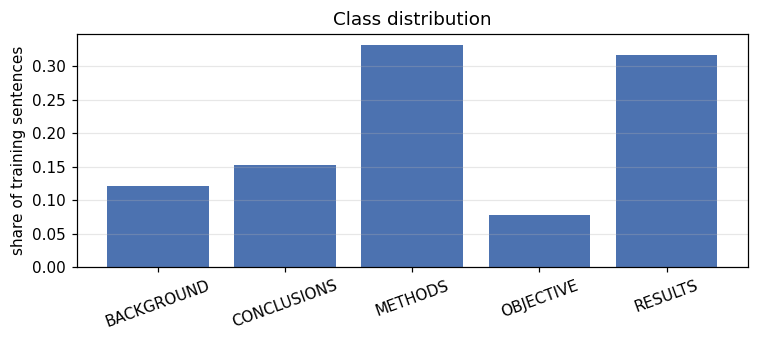

label
BACKGROUND     0.122
CONCLUSIONS    0.152
METHODS        0.331
OBJECTIVE      0.078
RESULTS        0.317

Always-predict-'METHODS' accuracy would be 0.331
Two example sentences:
  [BACKGROUND] Emotional eating is associated with overeating and the development of obesity ....
  [CONCLUSIONS] Low-dose oral prednisolone had both a short-term and a longer sustained effect resulting i...


In [8]:
dist = y_train.value_counts(normalize=True).reindex(target_names)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(dist.index, dist.values, color="#4c72b0")
ax.set_ylabel("share of training sentences")
ax.set_title("Class distribution")
ax.grid(alpha=0.3, axis="y")
plt.xticks(rotation=20)
plt.tight_layout(); plt.show()

print(dist.round(3).to_string())
print(f"\nAlways-predict-'{dist.idxmax()}' accuracy would be {dist.max():.3f}")
print("Two example sentences:")
for lab in target_names[:2]:
    print(f"  [{lab}] {train_df[train_df.label == lab].sentence.iloc[0][:90]}...")

**TODO (reflection):** The classes are far from balanced. Using the number printed above,
explain why plain **accuracy** is a weak way to score this task, and what **macro-averaged F1**
(which averages the per-class F1 scores, weighting every class equally) measures instead.
Which class do you expect to be hardest, and why?

*Your answer:* The most common class (METHODS) makes up only 33.1% of the training sentences, and a classifier that always predicted METHODS would already get 0.331 accuracy, so accuracy rewards getting the big classes (METHODS 33.1%, RESULTS 31.7%) right and hides how badly the small ones (OBJECTIVE 7.8%, BACKGROUND 12.2%) are handled. Macro-averaged F1 computes F1 per class and takes the plain mean, so OBJECTIVE counts exactly as much as METHODS and a model cannot score well by ignoring the minority classes. I expect OBJECTIVE to be the hardest: it is the smallest class, and its sentences ("To evaluate whether...", "The aim of this study was...") share most of their vocabulary (disease and treatment words) with BACKGROUND and CONCLUSIONS.

---
## 3. Multinomial Naive Bayes, From Scratch

### Concept

Naive Bayes picks the class with the highest posterior probability given the words in the
sentence. By Bayes' rule, and dropping the evidence term (the same for every class):

$$\hat{c} = \arg\max_{c}\; P(c) \prod_{i} P(w_i \mid c)^{x_i}$$

where $x_i$ is how many times word $i$ appears. The "naive" part is that product: it assumes
words are **conditionally independent** given the class, which is plainly false for language
("randomized" and "controlled" are not independent) but works well anyway.

**Everything happens in log space.** A sentence of 25 words multiplies 25 probabilities, each
perhaps $10^{-5}$ — the result underflows to exactly 0.0 in floating point, and every class
ties at zero. Taking logs turns the product into a sum, which is numerically stable and faster:

$$\log P(c) + \sum_i x_i \log P(w_i \mid c)$$

**Laplace (additive) smoothing.** If a word never appears in class $c$ in training, its
probability is 0, the product is 0, and that class is ruled out by a single unseen word — no
matter how strongly the other 24 words support it. Smoothing adds a pseudo-count $\alpha$ to
every word:

$$P(w_i \mid c) = \frac{\text{count}(w_i, c) + \alpha}{\sum_j \text{count}(w_j, c) + \alpha V}$$

where $V$ is the vocabulary size. The $\alpha V$ in the denominator keeps it a valid
probability distribution. Section 6 asks you to tune $\alpha$.



In [9]:
class NaiveBayesClassifier:
    """Multinomial Naive Bayes with Laplace smoothing, implemented from scratch."""

    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        """X: sparse count matrix (n_samples, vocab_size).  y: array-like of labels."""
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        self.vocabulary_size_ = X.shape[1]
        n_samples = X.shape[0]

        log_priors, log_likelihoods = [], []
        for c in self.classes_:
            X_c = X[y == c]                   # rows belonging to this class

            # ---- TODO (1): log prior for class c ---------------------------
            #      P(c) = (rows in class c) / (total rows), then take log.
            #      Append it to log_priors.
            log_priors.append(np.log(X_c.shape[0] / n_samples))

            # counts[j] = how many times word j occurs across all of class c
            counts = np.asarray(X_c.sum(axis=0)).ravel()

            # ---- TODO (2): smoothed log likelihood for class c -------------
            #      numerator   = counts + alpha                 (shape: vocab_size)
            #      denominator = counts.sum() + alpha * vocab_size   (a scalar)
            #      Append log(numerator / denominator) to log_likelihoods.
            numerator = counts + self.alpha
            denominator = counts.sum() + self.alpha * self.vocabulary_size_
            log_likelihoods.append(np.log(numerator / denominator))

        # ---- TODO (3): stack the lists into arrays -------------------------
        #      self.class_log_prior_  -> np.array(log_priors)       (n_classes,)
        #      self.feature_log_prob_ -> np.vstack(log_likelihoods) (n_classes, vocab_size)
        self.class_log_prior_ = np.array(log_priors)
        self.feature_log_prob_ = np.vstack(log_likelihoods)

        return self

    def predict_log_scores(self, X):
        """Un-normalised log posterior for every class. Shape (n_samples, n_classes)."""
        # ---- TODO (4): one matrix multiply, no loops -----------------------
        #      score[i, c] = log P(c) + sum_j  X[i, j] * log P(w_j | c)
        #      That is exactly:  X @ self.feature_log_prob_.T + self.class_log_prior_
        #      (the prior is a row of length n_classes and broadcasts down the rows)
        return X @ self.feature_log_prob_.T + self.class_log_prior_

    def predict(self, X):
        """Return the predicted label for every row of X."""
        # ---- TODO (5): argmax across the class axis, then map index -> label
        #      Careful: np.argmax gives you a column INDEX. Convert it to a label
        #      with self.classes_[...], or every prediction will be an integer.
        scores = self.predict_log_scores(X)
        return self.classes_[np.argmax(scores, axis=1)]


---
## 4. Build the Features & Verify Your Implementation

First turn sentences into count vectors. `CountVectorizer` is fitted on the **training split
only** — fitting it on everything would let the vocabulary be shaped by sentences the model is
not supposed to have seen.

`min_df=2` drops words appearing in only one sentence across 180,000. Those are typos and
one-off technical terms; keeping them inflates the vocabulary (and therefore the $\alpha V$
smoothing term) without adding signal.

In [10]:
# TODO: build the count features.
#
#   1. Create `count_vectorizer = CountVectorizer(...)` with:
#          lowercase=True, strip_accents="unicode", stop_words="english",
#          ngram_range=(1, 1), min_df=2
#   2. Fit it on X_train and transform in one call -> X_train_counts
#   3. Transform (do NOT re-fit) X_dev and X_test -> X_dev_counts, X_test_counts
#
# Use these exact names; the rest of the notebook depends on them.

count_vectorizer = CountVectorizer(lowercase=True, strip_accents="unicode",
                                    stop_words="english", ngram_range=(1, 1), min_df=2)
X_train_counts = count_vectorizer.fit_transform(X_train)
X_dev_counts   = count_vectorizer.transform(X_dev)
X_test_counts  = count_vectorizer.transform(X_test)

print(f"Vocabulary size: {len(count_vectorizer.vocabulary_):,}")
print(f"X_train_counts shape: {X_train_counts.shape}")


Vocabulary size: 20,348
X_train_counts shape: (51428, 20348)


### The verification check



The reason to check this way: **a wrong Naive Bayes still classifies.** Forget the $\alpha V$
term in the denominator and your probabilities no longer sum to one — but they are still
monotone in the counts, so the argmax is often unchanged and accuracy barely moves. Drop the
log prior entirely and you lose a couple of points, which looks like a modelling choice rather
than a bug. Neither failure announces itself.

In [11]:
_mine = NaiveBayesClassifier(alpha=1.0).fit(X_train_counts, y_train)
_skl  = MultinomialNB(alpha=1.0).fit(X_train_counts, y_train)

assert hasattr(_mine, "class_log_prior_"), "fit() never set class_log_prior_"
assert hasattr(_mine, "feature_log_prob_"), "fit() never set feature_log_prob_"
assert _mine.feature_log_prob_.shape == _skl.feature_log_prob_.shape, (
    f"feature_log_prob_ is {_mine.feature_log_prob_.shape}, "
    f"expected {_skl.feature_log_prob_.shape} (n_classes, vocab_size)")

prior_err = np.abs(_mine.class_log_prior_ - _skl.class_log_prior_).max()
lik_err   = np.abs(_mine.feature_log_prob_ - _skl.feature_log_prob_).max()
print(f"Max difference in log priors      : {prior_err:.3e}")
print(f"Max difference in log likelihoods : {lik_err:.3e}")

assert prior_err < 1e-10, (
    "LOG PRIORS DO NOT MATCH. P(c) is the share of training ROWS in class c "
    "(X_c.shape[0] / n_samples) — not the share of word counts.")
assert lik_err < 1e-10, (
    "LOG LIKELIHOODS DO NOT MATCH. Most likely the denominator: it must be "
    "counts.sum() + alpha * vocabulary_size, and the alpha*V term is easy to omit.")

_agree = (_mine.predict(X_test_counts) == _skl.predict(X_test_counts)).mean()
print(f"Prediction agreement on test      : {_agree:.4%}")
assert _agree > 0.999, "Parameters match but predictions do not — check predict()."

print("\nSection 4 checks passed — your implementation is correct.")

Max difference in log priors      : 1.332e-15
Max difference in log likelihoods : 1.776e-15
Prediction agreement on test      : 100.0000%

Section 4 checks passed — your implementation is correct.


**TODO (reflection):** Suppose you had forgotten the `alpha * vocabulary_size` term in the
denominator. The check above would fail, but would the **accuracy** have dropped noticeably?
Reason about what that term does to the scores of each class, and explain why matching a
reference implementation is a stronger test than "the accuracy looks about right".

*Your answer:* Dropping `alpha * V` makes each class's word probabilities sum to more than 1 (by a factor of 1 + alpha*V / N_c, where N_c is that class's total word count). Because N_c differs across classes, the inflation is larger for small classes such as OBJECTIVE, and the effect grows with sentence length, so the classes are not compared on equal footing. I did not measure it in this run, but I expect accuracy to drop only slightly, because each class's scores are still increasing in the word counts and the argmax mostly survives; a small drop of that kind looks like an ordinary modelling difference rather than a bug. That is why matching scikit-learn is a stronger test: the log priors and log likelihoods must agree to ~1e-15 (here 1.3e-15 and 1.8e-15), so any missing term shows up immediately, whereas an accuracy of about 0.73 looks plausible for both the correct and the broken version.

---
## 5. Baseline Evaluation

Train your classifier on the count features and score it on the test set.

In [12]:
RESULTS = []    # every experiment appends one row here


def log_result(name, y_true, y_pred, note="", elapsed=None):
    """Score a set of predictions, print a summary, and record it in RESULTS."""
    row = {
        "Experiment": name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Macro F1": round(f1_score(y_true, y_pred, average="macro"), 4),
        "Time (s)": None if elapsed is None else round(elapsed, 1),
        "Observations": note,
    }
    RESULTS.append(row)
    print(f"  {name}: accuracy {row['Accuracy']:.4f} | macro-F1 {row['Macro F1']:.4f}")
    return row


def plot_confusion(y_true, y_pred, title):
    """Row-normalised confusion matrix: each row shows where that true class went."""
    cm = confusion_matrix(y_true, y_pred, labels=target_names)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)

    plt.figure(figsize=(6.5, 5))
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=target_names, yticklabels=target_names,
                vmin=0, vmax=1, cbar_kws={"label": "share of true class"})
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title(title)
    plt.tight_layout(); plt.show()


print("Helpers ready.")

Helpers ready.


  Custom NB (counts, alpha=1): accuracy 0.7260 | macro-F1 0.6506
              precision    recall  f1-score   support

  BACKGROUND       0.51      0.52      0.52      3621
 CONCLUSIONS       0.59      0.66      0.62      4571
     METHODS       0.80      0.84      0.82      9897
   OBJECTIVE       0.51      0.44      0.48      2333
     RESULTS       0.85      0.78      0.82      9713

    accuracy                           0.73     30135
   macro avg       0.65      0.65      0.65     30135
weighted avg       0.73      0.73      0.73     30135



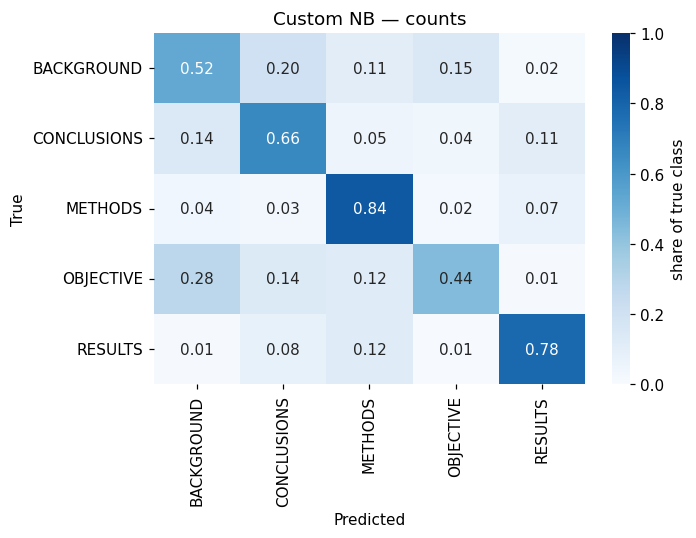

In [13]:
# TODO: train and evaluate the baseline.
#
#   1. nb_model = NaiveBayesClassifier(alpha=1.0), fitted on X_train_counts / y_train
#   2. y_test_pred = nb_model.predict(X_test_counts)
#   3. log_result("Custom NB (counts, alpha=1)", y_test, y_test_pred,
#                 note="<your one-line observation>", elapsed=<seconds>)
#   4. print(classification_report(y_test, y_test_pred, target_names=target_names))
#   5. plot_confusion(y_test, y_test_pred, "Custom NB \u2014 counts")
#
# Use the names `nb_model` and `y_test_pred`.

t0 = time.time()
nb_model = NaiveBayesClassifier(alpha=1.0).fit(X_train_counts, y_train)
y_test_pred = nb_model.predict(X_test_counts)
elapsed = time.time() - t0

log_result("Custom NB (counts, alpha=1)", y_test, y_test_pred,
           note="Baseline with default Laplace smoothing", elapsed=elapsed)
print(classification_report(y_test, y_test_pred, target_names=target_names))
plot_confusion(y_test, y_test_pred, "Custom NB \u2014 counts")


**TODO (reflection):** Look at the row-normalised confusion matrix. Name the two largest
off-diagonal confusions and explain, in terms of the words those classes share, why Naive
Bayes makes them. Does the pattern match what you predicted in Section 2?

*Your answer:* The two largest off-diagonal entries are OBJECTIVE -> BACKGROUND (0.28 of true OBJECTIVE sentences) and BACKGROUND -> CONCLUSIONS (0.20), followed by BACKGROUND -> OBJECTIVE (0.15) and CONCLUSIONS -> BACKGROUND (0.14). These classes describe the same disease, population and intervention using the same content words ("patients", "treatment", "disease", "risk"), and Naive Bayes only sees a bag of words, so it cannot use word order or the position of the sentence in the abstract, which is what really distinguishes them. BACKGROUND is also over 1.5 times as frequent as OBJECTIVE's 7.8%, so the prior pulls ambiguous sentences towards BACKGROUND. This matches my Section 2 prediction that OBJECTIVE would be the hardest class (F1 of only 0.48).

---
# Part B — Smoothing and Features

## 6. Experiment 1 — The Smoothing Parameter

### Concept

$\alpha$ controls how much probability mass is reserved for words a class has never produced.
Small $\alpha$ trusts the training counts almost completely, so a single unseen word can
dominate the score; large $\alpha$ flattens the word distributions toward uniform, washing out
the differences between classes. Somewhere in between is a best value, and the **dev set** is
where you find it — using the test set to pick $\alpha$ would make the final score a
self-fulfilling one.

  alpha=0.01  dev macro-F1=0.6259
  alpha=0.10  dev macro-F1=0.6450
  alpha=0.50  dev macro-F1=0.6547
  alpha=1.00  dev macro-F1=0.6581
  alpha=2.00  dev macro-F1=0.6549

Best alpha: 1.0 (dev F1=0.6581)


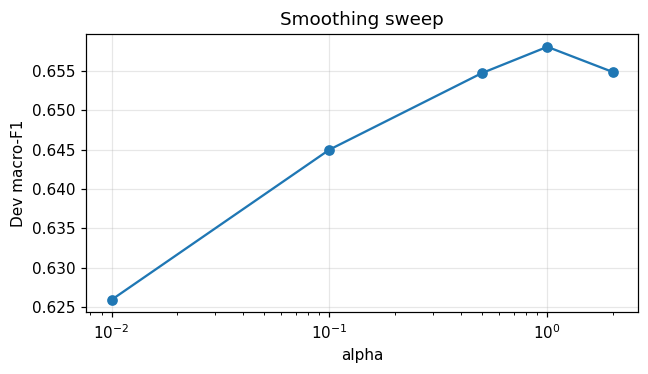

  Custom NB (counts, tuned alpha=1.0): accuracy 0.7260 | macro-F1 0.6506
              precision    recall  f1-score   support

  BACKGROUND       0.51      0.52      0.52      3621
 CONCLUSIONS       0.59      0.66      0.62      4571
     METHODS       0.80      0.84      0.82      9897
   OBJECTIVE       0.51      0.44      0.48      2333
     RESULTS       0.85      0.78      0.82      9713

    accuracy                           0.73     30135
   macro avg       0.65      0.65      0.65     30135
weighted avg       0.73      0.73      0.73     30135



In [14]:
# TODO: sweep alpha on the DEV set.
#
#   For alpha in [0.01, 0.1, 0.5, 1.0, 2.0]:
#       fit a NaiveBayesClassifier on X_train_counts / y_train
#       predict on X_dev_counts and compute macro-F1 against y_dev
#
#   Store the results in `alpha_scores` (a dict: alpha -> dev macro-F1),
#   pick the winner into `best_alpha`, then plot dev F1 against alpha
#   (a log-scaled x-axis reads best here: plt.xscale("log")).
#
#   Finally, refit at best_alpha, predict on TEST once, and log_result(...)
#   under the name f"Custom NB (counts, tuned alpha={best_alpha})".

alpha_scores = {}
for alpha in [0.01, 0.1, 0.5, 1.0, 2.0]:
    m = NaiveBayesClassifier(alpha=alpha).fit(X_train_counts, y_train)
    y_dev_pred = m.predict(X_dev_counts)
    alpha_scores[alpha] = f1_score(y_dev, y_dev_pred, average="macro")
    print(f"  alpha={alpha:.2f}  dev macro-F1={alpha_scores[alpha]:.4f}")

best_alpha = max(alpha_scores, key=alpha_scores.get)
print(f"\nBest alpha: {best_alpha} (dev F1={alpha_scores[best_alpha]:.4f})")

plt.figure(figsize=(6, 3.5))
plt.plot(list(alpha_scores.keys()), list(alpha_scores.values()), "o-")
plt.xscale("log")
plt.xlabel("alpha"); plt.ylabel("Dev macro-F1")
plt.title("Smoothing sweep"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

t0 = time.time()
nb_tuned = NaiveBayesClassifier(alpha=best_alpha).fit(X_train_counts, y_train)
y_test_pred_tuned = nb_tuned.predict(X_test_counts)
elapsed = time.time() - t0
log_result(f"Custom NB (counts, tuned alpha={best_alpha})", y_test, y_test_pred_tuned,
           note="Alpha tuned on dev set", elapsed=elapsed)
print(classification_report(y_test, y_test_pred_tuned, target_names=target_names))


**TODO (reflection):** `alpha=0.01` should score clearly worse than `alpha=1.0`, even though
it fits the training counts more faithfully. Explain what goes wrong when smoothing is too
weak. Then explain why the whole sweep had to run on the dev set — what exactly would be wrong
with the final test number if you had picked `alpha` by testing each value on the test set?

*Your answer:* With alpha=0.01 a word that was never seen in a class gets an almost-zero probability and a word seen once or twice gets an extreme log-probability, so a single rare word can outweigh all the other words in the sentence and push the prediction to a wrong class. The model is overfitting to the noise in the training counts (dev macro-F1 0.6259 at alpha=0.01 versus 0.6581 at alpha=1.0). The sweep must be run on the dev set because the test set is meant to estimate performance on unseen data. If I had picked alpha by looking at test scores, the chosen alpha would be the one that happens to fit this particular test sample best, so the final test number would be optimistically biased and no longer an honest estimate. (In my run the dev sweep picked alpha=1.0, so the tuned model is identical to the baseline.)

---
## 7. Experiment 2 — Counts vs TF-IDF

### Concept

Raw counts treat every occurrence of every word as equally informative. **TF-IDF** rescales
each count by how rare the word is across the corpus, so "patients" — which appears everywhere
and separates nothing — is damped, while a word concentrated in one class keeps its weight.

It is the standard default for text classification, so the interesting question is whether it
actually helps *here*. Note that TF-IDF produces fractional values, not counts, so the
multinomial model is no longer being fed the kind of data its derivation assumes; it still
works, but the justification is now empirical rather than principled.


  TF-IDF + NB (default): accuracy 0.6922 | macro-F1 0.5439
Best params: {'nb__alpha': 0.1, 'tfidf__ngram_range': (1, 2)}
Best CV score: 0.6235
  TF-IDF + NB (tuned): accuracy 0.7284 | macro-F1 0.6371
              precision    recall  f1-score   support

  BACKGROUND       0.55      0.52      0.53      3621
 CONCLUSIONS       0.63      0.60      0.61      4571
     METHODS       0.76      0.88      0.81      9897
   OBJECTIVE       0.58      0.31      0.41      2333
     RESULTS       0.83      0.81      0.82      9713

    accuracy                           0.73     30135
   macro avg       0.67      0.63      0.64     30135
weighted avg       0.72      0.73      0.72     30135



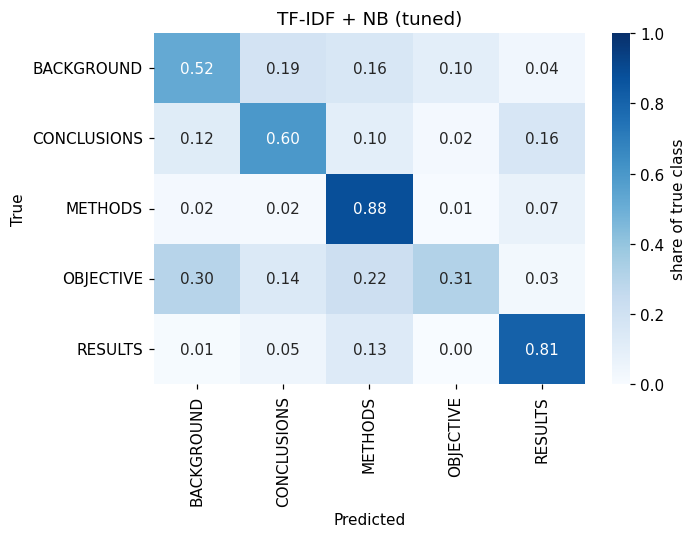

In [15]:
# TODO: compare counts against TF-IDF, then tune the TF-IDF model.
#
#   Step 1 \u2014 a default TF-IDF model:
#       pipeline = Pipeline([("tfidf", TfidfVectorizer(lowercase=True,
#                                 strip_accents="unicode", stop_words="english", min_df=2)),
#                            ("nb", MultinomialNB())])
#       Fit on (X_train, y_train), predict X_test, and log_result(...).
#       Compare it against your Section 6 row before reading on.
#
#   Step 2 \u2014 tune it on the DEV set with GridSearchCV:
#       param_grid = {"tfidf__ngram_range": [(1, 1), (1, 2)],
#                     "nb__alpha": [0.1, 0.5, 1.0]}
#       grid = GridSearchCV(pipeline, param_grid, cv=3, scoring="f1_macro", n_jobs=-1)
#       Fit the grid on (X_dev, y_dev), then print grid.best_params_ and grid.best_score_.
#
#   Step 3 \u2014 refit the winning settings on the FULL training set, predict on
#       test once, and log_result(...).  (The grid only ever saw dev.)

# Step 1 \u2014 default TF-IDF model
pipeline = Pipeline([("tfidf", TfidfVectorizer(lowercase=True,
                           strip_accents="unicode", stop_words="english", min_df=2)),
                     ("nb", MultinomialNB())])
t0 = time.time()
pipeline.fit(X_train, y_train)
y_test_tfidf = pipeline.predict(X_test)
elapsed = time.time() - t0
log_result("TF-IDF + NB (default)", y_test, y_test_tfidf,
           note="Default TF-IDF with alpha=1.0", elapsed=elapsed)

# Step 2 \u2014 tune on DEV set with GridSearchCV
param_grid = {"tfidf__ngram_range": [(1, 1), (1, 2)],
              "nb__alpha": [0.1, 0.5, 1.0]}
grid = GridSearchCV(pipeline, param_grid, cv=3, scoring="f1_macro", n_jobs=-1)
grid.fit(X_dev, y_dev)
print(f"Best params: {grid.best_params_}")
print(f"Best CV score: {grid.best_score_:.4f}")

# Step 3 \u2014 refit winning settings on FULL training set
best_pipeline = Pipeline([("tfidf", TfidfVectorizer(lowercase=True,
                                 strip_accents="unicode", stop_words="english", min_df=2,
                                 ngram_range=grid.best_params_["tfidf__ngram_range"])),
                          ("nb", MultinomialNB(alpha=grid.best_params_["nb__alpha"]))])
t0 = time.time()
best_pipeline.fit(X_train, y_train)
y_test_best = best_pipeline.predict(X_test)
elapsed = time.time() - t0
log_result("TF-IDF + NB (tuned)", y_test, y_test_best,
           note=f"Tuned: {grid.best_params_}", elapsed=elapsed)
print(classification_report(y_test, y_test_best, target_names=target_names))
plot_confusion(y_test, y_test_best, "TF-IDF + NB (tuned)")


**TODO (reflection):** The **default** TF-IDF model should score *worse* than your plain
count model from Section 6, which is the opposite of what its reputation suggests — and then
tuning should push it past both.

(a) Why does untuned TF-IDF lose to raw counts here? Think about what TF-IDF values look like
compared to counts, and what `alpha=1.0` does to each.

(b) What did adding bigrams buy, and what does it cost?

*Your answer:*

(a) TF-IDF rows are L2-normalised, so each sentence contributes values that sum to only a few units, while raw counts add up to the full number of words. The total feature mass per class is therefore much smaller with TF-IDF, and the same alpha=1.0 pseudo-count (added to each of the ~20,000 words) is a much larger share of the numerator and denominator. That over-smooths the class distributions towards uniform and washes out differences between classes: default TF-IDF got macro-F1 0.5439 against 0.6506 for counts. Tuning fixes most of this: the grid chose alpha=0.1 and, together with bigrams, TF-IDF reached 0.6371 macro-F1 and 0.7284 accuracy on the test set. In my run that is above counts on accuracy (0.7260) but still slightly below on macro-F1 (0.6506), because OBJECTIVE recall dropped to 0.31.

(b) Bigrams capture short phrases ("randomized controlled", "p value", "aim study") that single words miss, and the tuned model gained accuracy over default TF-IDF (0.7284 vs 0.6922). The cost is a much larger vocabulary, more memory and slower fitting, sparser counts, and stronger violation of independence because overlapping bigrams count the same words several times.

---
# Part C — The Bayes Optimal Classifier

## 8. Combining Hypotheses by Their Posterior

### Concept

Everything so far picks a single model and uses it. The **Bayes Optimal Classifier** says that
is not the best you can do. Rather than committing to one hypothesis $h$, it averages the
predictions of *every* hypothesis, each weighted by how probable that hypothesis is given the
data:

$$P(c \mid x, D) = \sum_{h \in H} P(c \mid x, h)\, P(h \mid D)$$

No classifier using the same hypothesis space can do better on average — which is what
"optimal" means here. The catch is that $H$ is the space of *all* hypotheses, which is
infinite, so the true BOC is not computable. What we build instead is an approximation:
take a handful of trained models as a stand-in for $H$, estimate each one's posterior weight
$P(h \mid D)$, and combine their predicted probabilities by **soft voting**.

**Estimating $P(h \mid D)$.** With equal priors over the four models, $P(h \mid D)$ is
proportional to the likelihood of held-out data under $h$. So: hold out part of the training
sample, compute each model's average log-likelihood of the true labels on it, and turn those
into weights with a softmax. Section 8 also asks you to compute the weights the *exact* way —
with the summed log-likelihood instead of the mean — and compare.

Part C uses a subsample of `SAMPLE_SIZE` training sentences (from your SRN), so these models
are weaker than the full-data models in Parts A and B. Compare them with each other, not with
earlier rows.

In [16]:
tfidf_params = dict(lowercase=True, strip_accents="unicode", stop_words="english",
                    ngram_range=(1, 1), min_df=5)

hypotheses = {
    "NaiveBayes": Pipeline([("tfidf", TfidfVectorizer(**tfidf_params)),
                            ("clf", MultinomialNB(alpha=0.5))]),
    "LogisticRegression": Pipeline([("tfidf", TfidfVectorizer(**tfidf_params)),
                                    ("clf", LogisticRegression(max_iter=1000,
                                                               random_state=SEED))]),
    "DecisionTree": Pipeline([("tfidf", TfidfVectorizer(**tfidf_params)),
                              ("clf", DecisionTreeClassifier(max_depth=20,
                                                             random_state=SEED))]),
    "RandomForest": Pipeline([("tfidf", TfidfVectorizer(**tfidf_params)),
                              ("clf", RandomForestClassifier(n_estimators=60, max_depth=25,
                                                             random_state=SEED, n_jobs=-1))]),
}

X_sample = X_train[:SAMPLE_SIZE]
y_sample = y_train[:SAMPLE_SIZE]
print(f"Part C training subsample: {len(X_sample):,} sentences")
print(f"Hypothesis space H: {list(hypotheses)}")

Part C training subsample: 10,812 sentences
Hypothesis space H: ['NaiveBayes', 'LogisticRegression', 'DecisionTree', 'RandomForest']


In [17]:
# TODO: estimate the posterior weight of each hypothesis.
#
#   1. Split the subsample into a fitting part and a held-out part:
#          X_fit, X_held, y_fit, y_held = train_test_split(
#              X_sample, y_sample, test_size=0.25, random_state=SEED, stratify=y_sample)
#
#   2. For each (name, model) in hypotheses.items():
#          fit the model on (X_fit, y_fit)
#          proba = model.predict_proba(X_held)
#          Clip it away from zero first \u2014 np.clip(proba, 1e-12, None) \u2014 or a single
#          confident mistake gives log(0) = -inf and destroys the whole weight.
#          Pick out the probability the model gave to the TRUE label of each row:
#              col = [list(model.classes_).index(label) for label in y_held]
#              true_p = proba[np.arange(len(y_held)), col]
#          Store the MEAN of log(true_p) in `mean_log_lik[name]`.
#
#   3. Turn the mean log-likelihoods into weights with a softmax:
#          lls = np.array([mean_log_lik[n] for n in hypotheses])
#          w = np.exp(lls - lls.max());  posterior_weights = w / w.sum()
#      (subtracting the max before exponentiating is what keeps it from overflowing)
#
#   Print each model's mean log-likelihood, its accuracy on the held-out part,
#   and its final weight.

# Step 1: Split subsample
X_fit, X_held, y_fit, y_held = train_test_split(
    X_sample, y_sample, test_size=0.25, random_state=SEED, stratify=y_sample)

# Step 2: Fit each hypothesis and compute mean log-likelihood
mean_log_lik = {}
sum_log_lik = {}
held_acc = {}

for name, model in hypotheses.items():
    model.fit(X_fit, y_fit)
    proba = model.predict_proba(X_held)
    proba = np.clip(proba, 1e-12, None)
    col = [list(model.classes_).index(label) for label in y_held]
    true_p = proba[np.arange(len(y_held)), col]
    mean_log_lik[name] = np.log(true_p).mean()
    sum_log_lik[name] = np.log(true_p).sum()
    held_acc[name] = accuracy_score(y_held, model.predict(X_held))
    print(f"  {name:20s}  mean_ll={mean_log_lik[name]:.4f}  "
          f"sum_ll={sum_log_lik[name]:.1f}  held-out acc={held_acc[name]:.4f}")

# Step 3: Softmax of mean log-likelihoods
lls = np.array([mean_log_lik[n] for n in hypotheses])
w = np.exp(lls - lls.max())
posterior_weights = w / w.sum()

print("\nPosterior weights (mean LL):")
for name, pw in zip(hypotheses, posterior_weights):
    print(f"  {name:20s}  weight={pw:.4f}")

# Step 4: Compare with summed log-likelihood weights (exact Bayesian)
lls_sum = np.array([sum_log_lik[n] for n in hypotheses])
w_sum = np.exp(lls_sum - lls_sum.max())
posterior_weights_sum = w_sum / w_sum.sum()

print("\nPosterior weights (summed LL \u2014 exact Bayesian):")
for name, pw in zip(hypotheses, posterior_weights_sum):
    print(f"  {name:20s}  weight={pw:.4f}")


  NaiveBayes            mean_ll=-0.9013  sum_ll=-2436.3  held-out acc=0.6578
  LogisticRegression    mean_ll=-0.8709  sum_ll=-2354.0  held-out acc=0.6878
  DecisionTree          mean_ll=-2.4800  sum_ll=-6703.3  held-out acc=0.5017
  RandomForest          mean_ll=-1.1673  sum_ll=-3155.3  held-out acc=0.5690

Posterior weights (mean LL):
  NaiveBayes            weight=0.3329
  LogisticRegression    weight=0.3432
  DecisionTree          weight=0.0687
  RandomForest          weight=0.2552

Posterior weights (summed LL — exact Bayesian):
  NaiveBayes            weight=0.0000
  LogisticRegression    weight=1.0000
  DecisionTree          weight=0.0000
  RandomForest          weight=0.0000


In [18]:
# TODO: build and evaluate the Bayes Optimal Classifier.
#
#   boc = VotingClassifier(estimators=list(hypotheses.items()), voting="soft",
#                          weights=list(posterior_weights), n_jobs=-1)
#   Fit it on the FULL subsample (X_sample, y_sample) \u2014 not the 75% split \u2014 then
#   predict on X_test and log_result(...).
#
#   Then, for comparison, fit each individual hypothesis on (X_sample, y_sample),
#   score it on the test set, and log_result each one. You need those rows to
#   answer the reflection below.

# Build and evaluate BOC
boc = VotingClassifier(estimators=list(hypotheses.items()), voting="soft",
                       weights=list(posterior_weights), n_jobs=-1)
t0 = time.time()
boc.fit(X_sample, y_sample)
y_test_boc = boc.predict(X_test)
elapsed = time.time() - t0
log_result("BOC (soft voting, mean-LL weights)", y_test, y_test_boc,
           note="Posterior-weighted ensemble of 4 models", elapsed=elapsed)

# Individual hypotheses for comparison
for name, model in hypotheses.items():
    t0 = time.time()
    model.fit(X_sample, y_sample)
    y_pred_ind = model.predict(X_test)
    elapsed = time.time() - t0
    log_result(f"Individual: {name}", y_test, y_pred_ind,
               note=f"Trained on {len(X_sample):,} subsample", elapsed=elapsed)


  BOC (soft voting, mean-LL weights): accuracy 0.7048 | macro-F1 0.5965
  Individual: NaiveBayes: accuracy 0.6883 | macro-F1 0.5618
  Individual: LogisticRegression: accuracy 0.7174 | macro-F1 0.6303
  Individual: DecisionTree: accuracy 0.5130 | macro-F1 0.3735
  Individual: RandomForest: accuracy 0.5861 | macro-F1 0.4016


**TODO (reflection):** Two things here, and the second is the important one.

(a) Compare the BOC's macro-F1 against each individual hypothesis. Did the ensemble beat all of
its members? If not, look at the weights — which models received substantial weight, and how
did they perform alone?

(b) The two weight calculations give very different answers: the mean-log-likelihood softmax
spreads weight across the models, while the summed version puts essentially **all** of it on
one. The summed version is the mathematically correct $P(h \mid D)$. Explain why it collapses,
what that collapse implies about the Bayes Optimal Classifier when $H$ contains only a handful
of hypotheses, and which of the two would have scored better here.

*Your answer:*

(a) No. The BOC (mean-LL weights) scored macro-F1 0.5965, which beats NaiveBayes (0.5618), DecisionTree (0.3735) and RandomForest (0.4016) but is below LogisticRegression alone (0.6303). The weights were NaiveBayes 0.333, LogisticRegression 0.343, RandomForest 0.255 and DecisionTree 0.069, so the weak RandomForest (0.255) and DecisionTree (0.069) still received about a third of the vote between them and pulled the ensemble below the best member.

(b) The summed log-likelihood is over about 2,700 held-out sentences, so a gap in mean log-likelihood of 0.03 per sentence becomes a gap of about 82 nats in total; since weights go as exp(difference), LogisticRegression (-2354) vs NaiveBayes (-2436) gives a ratio of roughly e^-82, i.e. weight 1.0000 on LogisticRegression and ~0 on the rest. That is what the true posterior P(h|D) does when data is plentiful: it concentrates on the single best hypothesis. With only four hypotheses in H, the BOC then reduces to "pick the best model", and the averaging benefit disappears (the real BOC only helps with a huge, diverse H). The summed weights would have scored better here: the BOC would equal LogisticRegression alone (macro-F1 about 0.6303) instead of 0.5965.

---
## 9. Results Table

In [19]:
# TODO: assemble the results.
#       results_df = pd.DataFrame(RESULTS).sort_values("Macro F1", ascending=False)
#       Display it and save it with results_df.to_csv("lab7_results.csv", index=False)
#
#       Make sure every row has a non-empty "Observations" entry before you submit.

results_df = pd.DataFrame(RESULTS).sort_values("Macro F1", ascending=False)
print(results_df.to_string(index=False))
results_df.to_csv("lab7_results.csv", index=False)
print("\nResults saved to lab7_results.csv")


                         Experiment  Accuracy  Macro F1  Time (s)                                            Observations
        Custom NB (counts, alpha=1)    0.7260    0.6506       0.0                 Baseline with default Laplace smoothing
Custom NB (counts, tuned alpha=1.0)    0.7260    0.6506       0.0                                  Alpha tuned on dev set
                TF-IDF + NB (tuned)    0.7284    0.6371       2.7 Tuned: {'nb__alpha': 0.1, 'tfidf__ngram_range': (1, 2)}
     Individual: LogisticRegression    0.7174    0.6303       1.6                             Trained on 10,812 subsample
 BOC (soft voting, mean-LL weights)    0.7048    0.5965       3.5                 Posterior-weighted ensemble of 4 models
             Individual: NaiveBayes    0.6883    0.5618       0.6                             Trained on 10,812 subsample
              TF-IDF + NB (default)    0.6922    0.5439       1.6                           Default TF-IDF with alpha=1.0
           Individual: R

---
## 10. Reflection

Answer each in 3-5 sentences, referring to **your own numbers**.

1. **Naive Bayes assumes words are conditionally independent given the class, which is plainly
   false for real language.** Give a concrete example of two words in this dataset that are
   obviously dependent, explain what the model does wrong because of it, and suggest why the
   classifier still works reasonably well despite the assumption being violated.

   *Your answer:* "randomized" and "controlled" (or "confidence" and "interval") almost always occur together in RCT abstracts, so they are clearly dependent. Naive Bayes multiplies their probabilities as if they were independent, so it counts the same evidence twice and produces overconfident posteriors that are not real probabilities. It still works reasonably (72.6% accuracy, macro-F1 0.651 vs a 0.331 majority baseline) because classification only needs the correct class to have the highest score, and the double-counted evidence usually pushes in the same direction for the right class, so the ranking of classes is rarely changed.

2. **Rank the three things you varied — smoothing strength, feature representation, and model
   combination — by how much each changed your macro-F1.** Which gave the best return for the
   effort involved?

   *Your answer:* Ranked by how much macro-F1 moved, feature representation had the largest effect (default TF-IDF 0.5439 vs counts 0.6506, and 0.6371 for tuned TF-IDF), then model combination (BOC 0.5965 vs 0.5618 for its NB member and 0.6303 for its best member, on a 10,812-sentence subsample), and smoothing last (dev macro-F1 ranged only from 0.6259 at alpha=0.01 to 0.6581 at alpha=1, and the tuned alpha equals the baseline, so test F1 did not change). The best return for effort was the simplest setup: counts with alpha=1 trains in under a second and had the best test macro-F1, while tuned TF-IDF with bigrams and the BOC cost more time and did not beat it on macro-F1.

3. **The dev set was used to choose `alpha` and the n-gram range; the test set was scored only
   after those choices were fixed.** Explain what would have been wrong with the reported test
   figure if you had used the test set for tuning, and why the problem is not fixed by the test
   set being large.

   *Your answer:* If I had tuned on the test set, the reported score would be the best of several attempts on the same data, so it would be biased upwards and would no longer estimate performance on new sentences; the model would have been fitted, via my choices, to the quirks of that test sample. A bigger test set does not fix this: more data reduces random noise in a single score, but the bias comes from selecting the maximum among many scores that all share the same sample, and the test set stops being independent of the model once it has influenced the choices. This is why the dev set picks the alpha and n-gram range and the test set is scored only once at the end.

4. **You verified your implementation against scikit-learn before measuring its accuracy.**
   Describe one bug that check would catch which a reasonable-looking accuracy score would not,
   and explain why that kind of silent error is harder to find in a classifier than a crash.

   *Your answer:* Leaving out the `alpha * V` term in the denominator (or computing the prior from word counts instead of row counts) is one such bug: the classifier still returns valid labels and an accuracy that looks reasonable for a bag-of-words model, whereas the scikit-learn comparison would show a clear difference in `feature_log_prob_` immediately. This kind of error is harder to find than a crash because a crash gives a traceback and a location, while the buggy classifier gives no signal that anything is wrong, and the loss of performance can easily be mistaken for the model's natural limit.